# Softmax

Softmax wandelt $M$ beliebige reelle Neuronen-Scores (**Logits**) $z_1,\ldots,z_M$ in Klassenwahrscheinlichkeiten um:

$$
p_j = \operatorname{softmax}(z)_j
= \frac{e^{z_j}}{\sum_{k=1}^{M} e^{z_k}},
\qquad j=1,\ldots,M.
$$

Jeder Wert liegt zwischen $0$ und $1$, und die Summe aller Werte ist $1$. Größere Logits ergeben größere Wahrscheinlichkeiten.

**Mini-Beispiel:** Ein MLP mit drei Outputneuronen liefert für ein Beispiel die Logits $z=(2;\,1;\,0)$. Zuerst exponentieren wir die Logits:

$$
(e^2;\,e^1;\,e^0) \approx (7{,}3891;\,2{,}7183;\,1).
$$

Dann teilen wir jeden Wert durch die Summe $e^2+e^1+e^0\approx11{,}1073$:

$$
\operatorname{softmax}(z)
\approx (0{,}6652;\,0{,}2447;\,0{,}0900).
$$

Die erste Klasse erhält also ungefähr $66{,}5\,\%$ Wahrscheinlichkeit. Auch ein Logit von $0$ ergibt eine positive Wahrscheinlichkeit, denn $e^0=1$.


In [1]:
import torch

# Ein Beispiel mit drei Klassen: direkte Ausgaben des MLP
logits = torch.tensor([2., 1., 0.])

# Formel zum Nachvollziehen
exp_logits = logits.exp()
p_manuell = exp_logits / exp_logits.sum()

# PyTorch berechnet Softmax numerisch stabil.
# dim=0: über die drei Klassen des eindimensionalen Tensors normalisieren.
p_softmax = torch.softmax(logits, dim=0)

print("Logits:", logits)
print("Exponentialwerte:", exp_logits)
print("Softmax manuell:", p_manuell)
print("Softmax mit PyTorch:", p_softmax)
# tensor([0.6652, 0.2447, 0.0900])
print("Summe der Wahrscheinlichkeiten:", p_softmax.sum())  # tensor(1.)

assert torch.allclose(p_manuell, p_softmax)

# Bei einem Batch der Form (N, M) verwendet man dim=1:
# p_batch = torch.softmax(logits_batch, dim=1)


Logits: tensor([2., 1., 0.])
Exponentialwerte: tensor([7.3891, 2.7183, 1.0000])
Softmax manuell: tensor([0.6652, 0.2447, 0.0900])
Softmax mit PyTorch: tensor([0.6652, 0.2447, 0.0900])
Summe der Wahrscheinlichkeiten: tensor(1.)


# MSE

MSE = Mean Squared Error = Mittlerer quadratischer Fehler

Beispiel mit Minibatchsize N = 4 und 3 Outputneuronen:

$$
L_{\mathrm{MSE}}
=
\frac{1}{N \cdot M}
\sum_{i=1}^{N}
\sum_{j=1}^{M}
\left(\hat{y}_{ij} - y_{ij}\right)^2
$$

Dabei ist:
- $N$: Anzahl der Beispiele im Batch
- $M$: Anzahl der Outputneuronen
- $\hat{y}_{ij}$: Ist-Output von Neuron $j$ für Beispiel $i$
- $y_{ij}$: entsprechender Soll-Output

## Berechnung mit PyTorch nn.MSELoss

https://docs.pytorch.org/docs/2.15/generated/torch.nn.MSELoss.html

In [2]:
import torch

# Vier Beispiele mit jeweils drei Outputwerten
ist = torch.tensor([
    [2., 4., 3.],
    [4., 4., 7.],
    [5., 8., 8.],
    [2., 4., 6.],
])

soll = torch.tensor([
    [1., 2., 3.],
    [4., 5., 6.],
    [7., 8., 9.],
    [1., 2., 3.],
])

loss_fn = nn.MSELoss()  # Standard: reduction="mean"
loss = loss_fn(ist, soll)
loss

tensor(2.1667)

Der entscheidende Punkt bei `nn.MSELoss`:

PyTorch teilt hier die Summe der Fehler durch zwölf, nicht nur durch die Batchgröße vier. Der resultierende Loss ist eine einzelne Zahl, die den mittleren quadratischen Fehler über den gesamten Batch ausdrückt.

Der Loss ist also der mittlere quadratische Fehler, wobei gemittelt wird über:
- alle Beispiel im Batch
UND
- alle Outputneurone

## Berechnung manuell

In [3]:
ist-soll

tensor([[ 1.,  2.,  0.],
        [ 0., -1.,  1.],
        [-2.,  0., -1.],
        [ 1.,  2.,  3.]])

In [ ]:
(ist-soll)**2

tensor([[1., 4., 0.],
        [0., 1., 1.],
        [4., 0., 1.],
        [1., 4., 9.]])

In [5]:
((ist-soll)**2).mean()

tensor(2.1667)

# Cross-Entropy-Loss

Der Cross-Entropy-Loss bewertet bei einer Klassifikation, wie viel Wahrscheinlichkeit das Modell der richtigen Klasse zuweist: Je kleiner diese Wahrscheinlichkeit ist, desto größer ist der Loss.

Wenn man Wahrscheinlichkeiten für die Klassen vorhergesagt hat:

$$
L_{\mathrm{CE}}
=
-\frac{1}{N}
\sum_{i=1}^{N}
\sum_{j=1}^{M}
y_{ij}\,\ln(p_{ij})
$$

Dabei ist:
- $N$: Anzahl der Beispiele im Batch
- $M$: Anzahl der Klassen beziehungsweise Outputneuronen
- $p_{ij}$: vorhergesagte Wahrscheinlichkeit für Klasse $j bei Beispiel $i
- $y_{ij}$: Soll-Output in One-Hot-Darstellung: $1$ für die richtige Klasse, ansonsten $0$
- $ln$: natürlicher Logarithmus

Intern arbeitet PyTorch mit logits, nicht mit den Wahrscheinlichkeiten und rechnet aus:

$$
L_{\mathrm{CE}}
=
-\frac{1}{N}
\sum_{i=1}^{N}
\ln\left(
\frac{e^{z_{i,c_i}}}
{\sum_{j=1}^{M}e^{z_{ij}}}
\right)
$$

Hierbei sei bei Beispiel $i$ die richtige Klasse: $c_i$

## Berechnung mit Pytorch nn.CrossEntropyLoss

https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html

In [6]:
import torch
from torch import nn

wahrscheinlichkeiten = torch.tensor([
    [0.7, 0.2, 0.1],
    [0.1, 0.6, 0.3],
    [0.2, 0.2, 0.6],
    [0.1, 0.8, 0.1],
])

# Für dieses Rechenbeispiel passende Logits:
# softmax(log(p)) = p, weil jede Zeile von p die Summe 1 hat.
logits = wahrscheinlichkeiten.log()

# Klassenindizes: A = 0, B = 1, C = 2
soll_klassen = torch.tensor([0, 1, 2, 0])

loss_fn = nn.CrossEntropyLoss()  # reduction="mean"
loss = loss_fn(logits, soll_klassen)

print(loss)  # tensor(0.9202)

tensor(0.9202)


## Berechnung manuell mit Wahrscheinlichkeiten

In [13]:
wahrscheinlichkeiten

tensor([[0.7000, 0.2000, 0.1000],
        [0.1000, 0.6000, 0.3000],
        [0.2000, 0.2000, 0.6000],
        [0.1000, 0.8000, 0.1000]])

In [12]:
soll_klassen

tensor([0, 1, 2, 0])

In [10]:
p_richtig = wahrscheinlichkeiten[[0,1,2,3], soll_klassen]
p_richtig

tensor([0.7000, 0.6000, 0.6000, 0.1000])

In [14]:
loss_manuell = -p_richtig.log().mean()
print(loss_manuell)  # tensor(0.9202)

tensor(0.9202)


## Berechnung manuell mit Logits

Wir verwenden dieselben `logits` und `soll_klassen` wie oben. Für jedes Beispiel wählen wir den Logit der Soll-Klasse aus, berechnen dessen Softmax-Wahrscheinlichkeit und wenden den negativen natürlichen Logarithmus an. Anschließend mitteln wir über die $N$ Beispiele:

$$
L_{\mathrm{CE}}
=
-\frac{1}{N}
\sum_{i=1}^{N}
\ln\left(
\frac{e^{z_{i,c_i}}}
{\sum_{j=1}^{M}e^{z_{ij}}}
\right)
$$

Dabei ist $z_{ij}$ der Logit für Klasse $j$ bei Beispiel $i$ und $c_i$ die richtige Klasse (im Code beginnen Klassenindizes bei `0`). Es ergibt sich bis auf Rundungsfehler derselbe Loss wie bei der Berechnung mit Wahrscheinlichkeiten und mit `nn.CrossEntropyLoss()`: ungefähr **0,9202**.

Die direkte Berechnung mit Exponentialfunktion und Logarithmus dient hier zum Nachvollziehen der Formel. PyTorch kombiniert diese Schritte numerisch stabil. Die äquivalente stabile Berechnung mit `torch.logsumexp` zeigen wir ebenfalls.


In [25]:
# 1. Die Exponentialfunktion auf jeden Logit anwenden.
exp_logits = logits.exp()

# 2. Pro Beispiel über alle M Klassen summieren.
nenner = exp_logits.sum(dim=1)

# 3. Pro Beispiel den Wert für die richtige Klasse auswählen.
beispiel_indizes = torch.arange(logits.shape[0], device=logits.device)
zaehler = exp_logits[beispiel_indizes, soll_klassen]

# 4. Wahrscheinlichkeit der richtigen Klasse und einzelnen Loss berechnen.
p_richtig_aus_logits = zaehler / nenner
loss_pro_beispiel = -p_richtig_aus_logits.log()

# 5. Über die N Beispiele mitteln.
loss_manuell_logits = loss_pro_beispiel.mean()
loss_manuell_logits

tensor(0.9202)

In [20]:
exp_logits

tensor([[0.7000, 0.2000, 0.1000],
        [0.1000, 0.6000, 0.3000],
        [0.2000, 0.2000, 0.6000],
        [0.1000, 0.8000, 0.1000]])

In [21]:
nenner

tensor([1., 1., 1., 1.])

In [22]:
beispiel_indizes

tensor([0, 1, 2, 3])

In [23]:
zaehler

tensor([0.7000, 0.6000, 0.6000, 0.1000])

In [24]:
loss_pro_beispiel

tensor([0.3567, 0.5108, 0.5108, 2.3026])

## Plot für -ln(p)

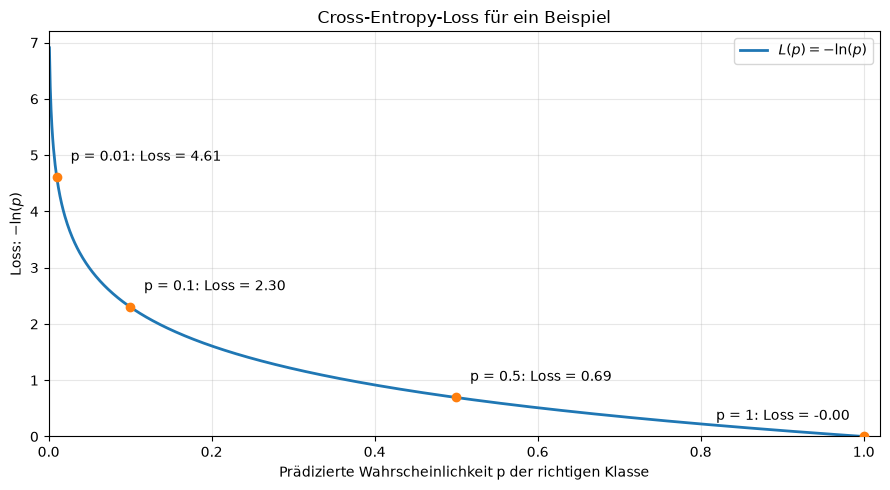

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# p ist die Wahrscheinlichkeit, die das Modell der richtigen Klasse zuweist.
# p = 0 ist ausgeschlossen, weil -ln(p) dort gegen unendlich geht.
p = np.linspace(0.001, 1.0, 1000)
loss = -np.log(p)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(p, loss, linewidth=2, label=r"$L(p) = -\ln(p)$")

# Einige konkrete Wahrscheinlichkeiten und ihre Loss-Werte markieren.
p_beispiele = np.array([0.01, 0.1, 0.5, 1.0])
loss_beispiele = -np.log(p_beispiele)
ax.scatter(p_beispiele, loss_beispiele, color="tab:orange", zorder=3)
for p_wert, loss_wert in zip(p_beispiele, loss_beispiele):
    ax.annotate(
        f"p = {p_wert:g}: Loss = {loss_wert:.2f}",
        (p_wert, loss_wert),
        xytext=(-10 if p_wert == 1.0 else 10, 12),
        textcoords="offset points",
        ha="right" if p_wert == 1.0 else "left",
    )

ax.set(
    xlabel="Prädizierte Wahrscheinlichkeit p der richtigen Klasse",
    ylabel=r"Loss: $-\ln(p)$",
    title="Cross-Entropy-Loss für ein Beispiel",
    xlim=(0, 1.02),
    ylim=(0, 7.2),
)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


# Einfacher Vergleich: BCELoss und CrossEntropyLoss

Wir wollen für vier E-Mails entscheiden: **kein Spam (0) oder Spam (1)?**

Für diese Aufgabe können wir beide Losses verwenden. Wir benutzen dieselben Vorhersagen und zeigen, dass derselbe Loss herauskommt.

## 1. CrossEntropyLoss: zwei Outputneuronen

Ein Outputneuron steht für **kein Spam**, das andere für **Spam**. Das Modell liefert zwei Logits pro E-Mail. Der größere Wert bedeutet, dass das Modell diese Klasse bevorzugt.

| E-Mail | Logits (kein Spam, Spam) | Tatsächlich Spam? |
|---|---|---|
| 1 | (0, 2) | Ja (1) |
| 2 | (2, 0) | Nein (0) |
| 3 | (1, 0) | Ja (1) |
| 4 | (0, 1) | Nein (0) |

Die ersten beiden Vorhersagen sind richtig, die letzten beiden falsch. Wir übergeben die Logits direkt an `CrossEntropyLoss`.


In [2]:
import torch
from torch import nn

# Spalte 0: kein Spam, Spalte 1: Spam
spam_logits = torch.tensor([
    [0., 2.],
    [2., 0.],
    [1., 0.],
    [0., 1.],
])
spam_soll = torch.tensor([1, 0, 1, 0])

spam_loss_ce = nn.CrossEntropyLoss()(spam_logits, spam_soll)
print("CrossEntropyLoss:", spam_loss_ce.item())  # ca. 0.7201


CrossEntropyLoss: 0.7200948596000671


## 2. BCELoss: eine Wahrscheinlichkeit pro E-Mail

Bei `BCELoss` genügt **die Wahrscheinlichkeit für Spam**. Die Wahrscheinlichkeit für kein Spam ist automatisch $1-p$.

Damit wir genau dieselben Vorhersagen vergleichen, rechnen wir die obigen Logits mit Softmax in Wahrscheinlichkeiten um und nehmen die Spam-Spalte:

| E-Mail | Wahrscheinlichkeit für Spam | Tatsächlich Spam? |
|---|---|---|
| 1 | ca. 0,881 | Ja (1) |
| 2 | ca. 0,119 | Nein (0) |
| 3 | ca. 0,269 | Ja (1) |
| 4 | ca. 0,731 | Nein (0) |

Diese Wahrscheinlichkeiten können wir direkt an `BCELoss` übergeben. Die Sollwerte müssen hier Gleitkommazahlen sein.


In [3]:
spam_wahrscheinlichkeiten = torch.softmax(spam_logits, dim=1)
p_spam = spam_wahrscheinlichkeiten[:, 1]  # Nur die Spam-Spalte
print("Spam-Wahrscheinlichkeiten:", p_spam)
# tensor([0.8808, 0.1192, 0.2689, 0.7311])

spam_loss_bce = nn.BCELoss()(p_spam, spam_soll.float())
print("BCELoss:", spam_loss_bce.item())  # ca. 0.7201
print("CrossEntropyLoss:", spam_loss_ce.item())  # ca. 0.7201
print("Gleicher Loss?", torch.allclose(spam_loss_bce, spam_loss_ce))  # True


Spam-Wahrscheinlichkeiten: tensor([0.8808, 0.1192, 0.2689, 0.7311])
BCELoss: 0.7200948596000671
CrossEntropyLoss: 0.7200948596000671
Gleicher Loss? True


## Warum kommt dasselbe heraus?

Beide Losses nehmen für jede E-Mail den negativen Logarithmus der Wahrscheinlichkeit der **richtigen Antwort**:

- Ist die E-Mail Spam, verwenden wir $-\ln(p_{\mathrm{Spam}})$.
- Ist sie kein Spam, verwenden wir $-\ln(1-p_{\mathrm{Spam}})$.

Danach mitteln wir über die vier E-Mails:

$$
L \approx \frac{0{,}1269+0{,}1269+1{,}3133+1{,}3133}{4}
\approx 0{,}7201.
$$

**Der Unterschied im Beispiel:** `CrossEntropyLoss` bekommt zwei Logits pro E-Mail. `BCELoss` bekommt nur die Spam-Wahrscheinlichkeit pro E-Mail. Bei denselben Vorhersagen liefern sie denselben Loss.

Ein eigenes MLP für `BCELoss` könnte deshalb mit **einem Outputneuron und Sigmoid** enden. Hier haben wir die Wahrscheinlichkeit aus den zwei Logits übernommen, damit der Vergleich exakt dieselben Vorhersagen verwendet.
